In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("data/airline.csv")

## Missing value

In [2]:
missing = pd.DataFrame({
    "so_luong_thieu": df.isna().sum(),
    "ty_le_thieu": df.isna().mean() * 100
})
missing = missing[missing["so_luong_thieu"] > 0]
missing["ty_le_thieu"] = missing["ty_le_thieu"].round(2)
print("Các cột có missing:")
print(missing)

Các cột có missing:
                          so_luong_thieu  ty_le_thieu
Arrival Delay in Minutes             393          0.3


## Duplicate

In [3]:
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số id bị trùng:", df["id"].duplicated().sum())

Số dòng trùng hoàn toàn: 0
Số id bị trùng: 0


## Biến phân loại

In [14]:
cat_cols = ["Gender", "Customer Type", "Type of Travel", "Class", "satisfaction"]

for col in cat_cols:
    print("\n")
    print(df[col].value_counts())



Gender
Female    65899
Male      63981
Name: count, dtype: int64


Customer Type
Loyal Customer       106100
disloyal Customer     23780
Name: count, dtype: int64


Type of Travel
Business travel    89693
Personal Travel    40187
Name: count, dtype: int64


Class
Business    62160
Eco         58309
Eco Plus     9411
Name: count, dtype: int64


satisfaction
neutral or dissatisfied    73452
satisfied                  56428
Name: count, dtype: int64


## Biến số

In [18]:
num_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]
print(df[num_cols].describe().T.to_string())

                               count         mean         std   min    25%    50%     75%     max
Age                         129880.0    39.427957   15.119360   7.0   27.0   40.0    51.0    85.0
Flight Distance             129880.0  1190.316392  997.452477  31.0  414.0  844.0  1744.0  4983.0
Departure Delay in Minutes  129880.0    14.713713   38.071126   0.0    0.0    0.0    12.0  1592.0
Arrival Delay in Minutes    129487.0    15.091129   38.465650   0.0    0.0    0.0    13.0  1584.0


## Outlier của biến số (IQR)

In [19]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df.loc[(df[col] < lower) | (df[col] > upper), col]

    print("\n", col)
    print("Ngưỡng dưới:", lower, "| Ngưỡng trên:", upper)
    print("Số outlier:", len(outliers),
          f"({len(outliers) / df[col].notna().sum() * 100:.2f}%)")
    if len(outliers) > 0:
        print("Các giá trị outlier (giá trị: số lần xuất hiện):")
        print(outliers.value_counts().sort_index())


 Age
Ngưỡng dưới: -9.0 | Ngưỡng trên: 87.0
Số outlier: 0 (0.00%)

 Flight Distance
Ngưỡng dưới: -1581.0 | Ngưỡng trên: 3739.0
Số outlier: 2855 (2.20%)
Các giá trị outlier (giá trị: số lần xuất hiện):
Flight Distance
3740    12
3741     8
3742    10
3743    13
3744    12
        ..
4243    23
4502    14
4817     6
4963    19
4983    16
Name: count, Length: 266, dtype: int64

 Departure Delay in Minutes
Ngưỡng dưới: -18.0 | Ngưỡng trên: 30.0
Số outlier: 18098 (13.93%)
Các giá trị outlier (giá trị: số lần xuất hiện):
Departure Delay in Minutes
31      526
32      467
33      407
34      424
35      413
       ... 
978       1
1017      1
1128      1
1305      1
1592      1
Name: count, Length: 435, dtype: int64

 Arrival Delay in Minutes
Ngưỡng dưới: -19.5 | Ngưỡng trên: 32.5
Số outlier: 17492 (13.51%)
Các giá trị outlier (giá trị: số lần xuất hiện):
Arrival Delay in Minutes
33.0      473
34.0      453
35.0      391
36.0      445
37.0      387
         ... 
970.0       1
1011.0      1
11

## Skewness và kurtosis

                            skewness  kurtosis
Age                            -0.00     -0.72
Flight Distance                 1.11      0.27
Departure Delay in Minutes      6.82    100.64
Arrival Delay in Minutes        6.67     95.12


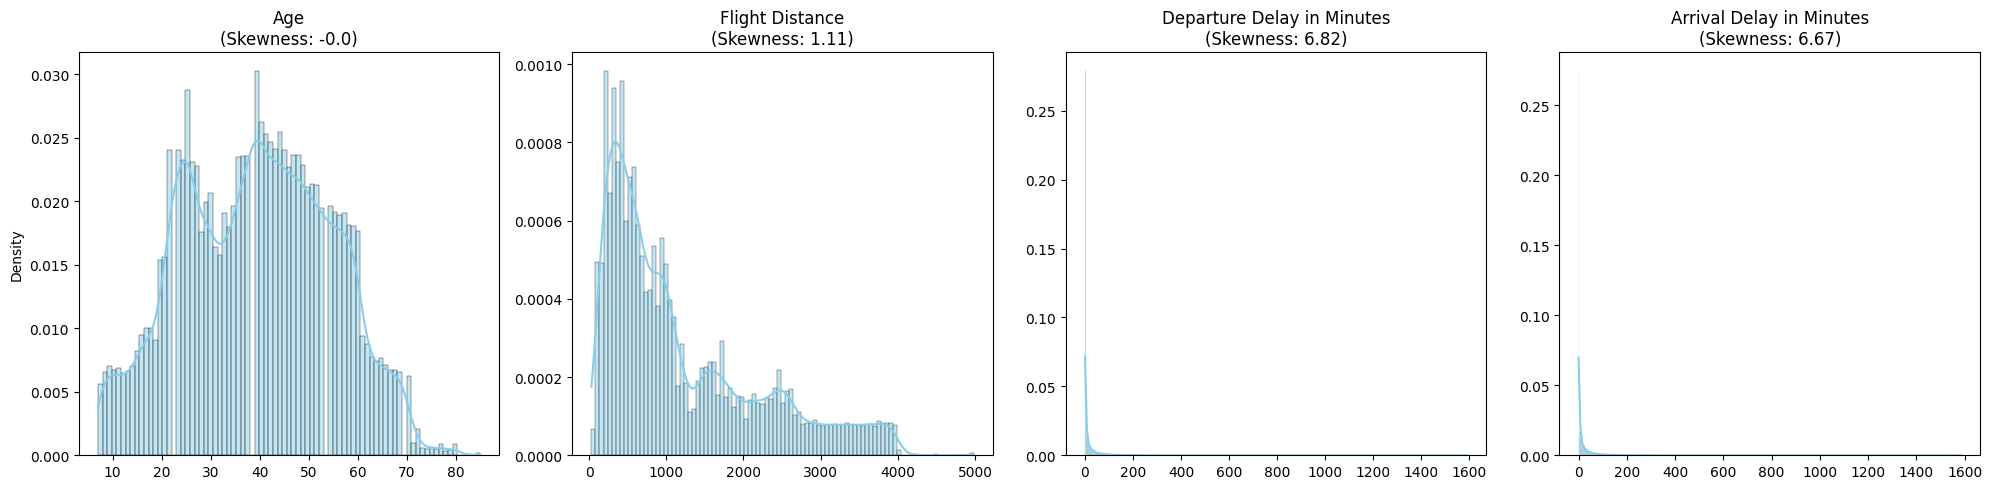

In [7]:
shape = pd.DataFrame({
    "skewness": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt()
}).round(2)
print(shape)

n_col = len(num_cols)
fig, axes = plt.subplots(1, n_col, figsize=(5 * n_col, 5))
if n_col == 1:
    axes = [axes]
for i, col in enumerate(num_cols):
    skew_val = shape.loc[col, 'skewness']
    sns.histplot(df[col], stat='density', kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'{col}\n(Skewness: {skew_val})', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Density' if i == 0 else '')
plt.tight_layout()
plt.show()

## Điểm dịch vụ

In [8]:
service_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

service_range = pd.DataFrame({
    "min": df[service_cols].min(),
    "max": df[service_cols].max(),
    "so_luong_0": (df[service_cols] == 0).sum()
})
print(service_range)

                                   min  max  so_luong_0
Inflight wifi service                0    5        3916
Departure/Arrival time convenient    0    5        6681
Ease of Online booking               0    5        5682
Gate location                        0    5           1
Food and drink                       0    5         132
Online boarding                      0    5        3080
Seat comfort                         0    5           1
Inflight entertainment               0    5          18
On-board service                     0    5           5
Leg room service                     0    5         598
Baggage handling                     1    5           0
Checkin service                      0    5           1
Inflight service                     0    5           5
Cleanliness                          0    5          14


## Boxplot biến số

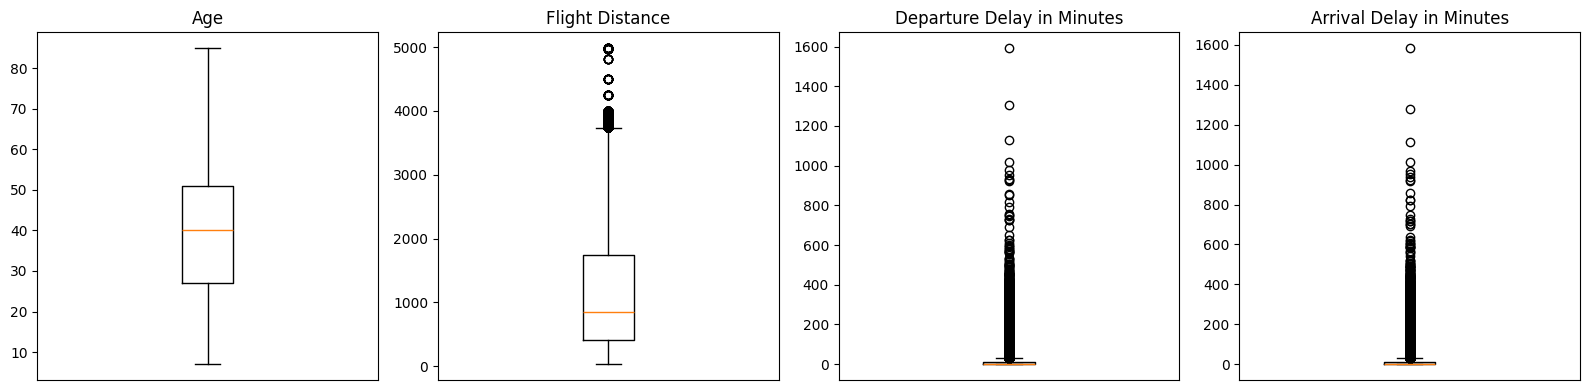

In [9]:
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])

plt.tight_layout()
plt.savefig("figures/02_boxplot_bien_so.png", dpi=150)
plt.show()

## Tương quan giữa các biến số

In [10]:
num_corr = df[num_cols].corr(method="spearman").round(2)
display(num_corr)

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
Age,1.00,0.07,-0.01,-0.01
Flight Distance,0.07,1.00,0.03,-0.00
Departure Delay in Minutes,-0.01,0.03,1.00,0.74
Arrival Delay in Minutes,-0.01,-0.00,0.74,1.00


## Tương quan giữa các điểm dịch vụ

Các cặp tiêu chí tương quan cao nhất:
Inflight wifi service   Ease of Online booking    0.69
Inflight entertainment  Cleanliness               0.68
Seat comfort            Cleanliness               0.67
Food and drink          Cleanliness               0.65
Baggage handling        Inflight service          0.63
Food and drink          Inflight entertainment    0.61
Seat comfort            Inflight entertainment    0.60
On-board service        Inflight service          0.57
Food and drink          Seat comfort              0.56
On-board service        Baggage handling          0.54
dtype: float64


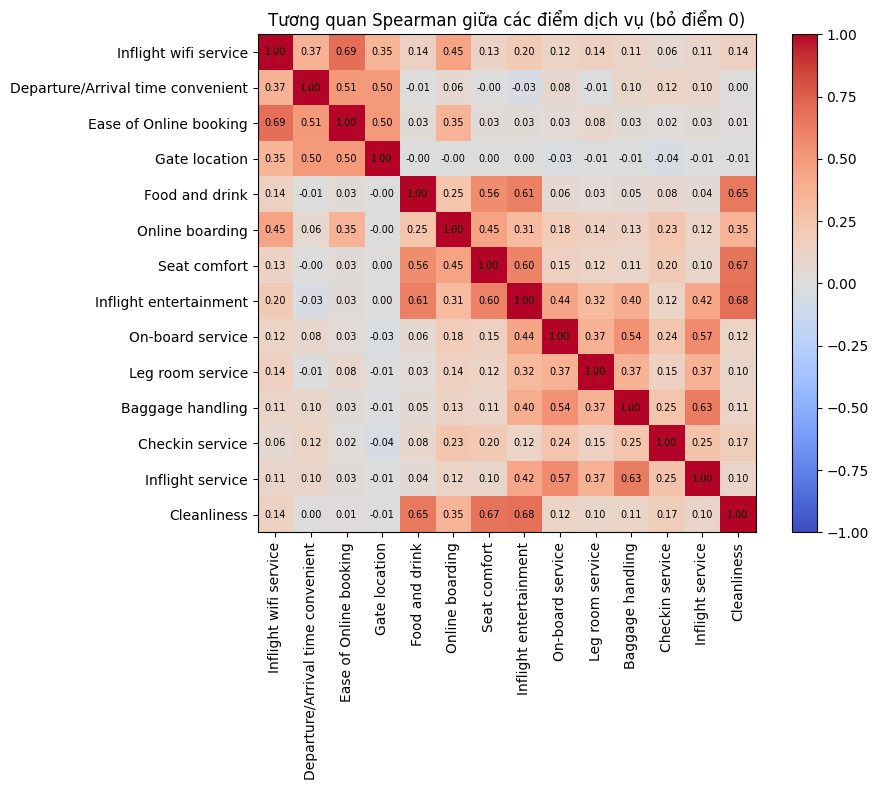

In [20]:
service_data = df[service_cols].mask(df[service_cols] == 0)
service_corr = service_data.corr(method="spearman")

# In các cặp tương quan cao nhất (mỗi cặp chỉ lấy một lần)
pairs = service_corr.where(
    np.triu(np.ones(service_corr.shape, dtype=bool), k=1)
).stack().sort_values(ascending=False)
print("Các cặp tiêu chí tương quan cao nhất:")
print(pairs.head(10).round(2))

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(service_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(service_cols)))
ax.set_xticklabels(service_cols, rotation=90)
ax.set_yticks(range(len(service_cols)))
ax.set_yticklabels(service_cols)
for i in range(len(service_cols)):
    for j in range(len(service_cols)):
        ax.text(j, i, f"{service_corr.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax)
ax.set_title("Tương quan Spearman giữa các điểm dịch vụ (bỏ điểm 0)")

plt.tight_layout()
plt.savefig("figures/02_heatmap_dich_vu.png", dpi=150)
plt.show()